# Hotel Success Prediction Using Real and Synthetic Data

### Review 1 – Data Analysis and Predictive Modelling

**Project:** Hotel Success Prediction  
**Dataset:** Real + Synthetic Hotel Dataset  
**Unit of analysis:** Hotel  
**Target variable:** `success`




In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.decomposition import PCA

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [ ]:
# Load the combined real + synthetic hotel dataset



file_path = "combined_real_synthetic_hotels.csv"

raw_df = pd.read_csv(file_path)


df = raw_df.copy()

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully.
Shape: (4572, 31)


,hotel_id,hotel_name,location,hotel_category,price,log_price,customer_rating,review_count,amenities,latitude,longitude,amenity_count,amenity_air_conditioning,amenity_room_service,amenity_full_service_laundry,amenity_free_wi_fi,amenity_kid_friendly,amenity_restaurant,amenity_free_breakfast,amenity_free_parking,amenity_airport_shuttle,amenity_accessible,amenity_kitchen_in_some_rooms,amenity_smoke_free_property,amenity_breakfast_($),amenity_bar,amenity_parking,PCA1,PCA2,success,data_type
0,ChUImcGzjY7CnO55GgkvbS8wOV80NDYQAQ,"The Oberoi Grand, Kolkata",Kolkata,5-star hotel,NaN,NaN,4.4,30193.0,accessible | air conditioning | airport shuttl...,NaN,NaN,29,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,29.093810,7.626926,1,Real
1,ChYI-PvamN_4iPVCGgovbS8waF9jNzY1EAE,The Accord Metropolitan,Chennai,5-star hotel,7961.0,8.982436,4.4,12467.0,accessible | air conditioning | bar | business...,13.046032,80.242575,27,1,1,1,1,1,1,1,1,0,1,1,0,0,1,1,26.769821,7.039099,1,Real
2,ChYI29ajs42Eye9DGgovbS8wcGQ5OHB5EAE,The Westin Chennai Velachery,Chennai,5-star hotel,15306.0,9.636066,4.4,12767.0,accessible | air conditioning | airport shuttl...,12.989379,80.220885,27,1,1,0,1,1,1,0,1,1,1,1,1,0,1,1,26.489378,5.132329,1,Real
3,ChYI2LPGxbrC7a9cGgovbS8wd2ZnMjc3EAE,"ITC Grand Central, a Luxury Collection Hotel, ...",Mumbai,5-star hotel,33024.0,10.405020,4.7,24017.0,accessible | air conditioning | bar | business...,NaN,NaN,23,1,1,1,1,1,1,0,1,0,1,0,0,0,1,1,22.490937,4.316875,1,Real
4,ChYI2qaDle7V6PssGgovbS8wajI0ZmMyEAE,Diggi Palace – A Heritage Hotel,Jaipur,4-star hotel,6987.0,8.851950,4.4,5193.0,accessible | air conditioning | bar | free bre...,26.909902,75.812471,23,1,1,1,1,1,1,1,1,0,1,0,0,0,1,1,22.890144,5.328603,1,Real


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nDataset information:")
df.info()

Number of rows: 4572
Number of columns: 31

Column names:
['hotel_id', 'hotel_name', 'location', 'hotel_category', 'price', 'log_price', 'customer_rating', 'review_count', 'amenities', 'latitude', 'longitude', 'amenity_count', 'amenity_air_conditioning', 'amenity_room_service', 'amenity_full_service_laundry', 'amenity_free_wi_fi', 'amenity_kid_friendly', 'amenity_restaurant', 'amenity_free_breakfast', 'amenity_free_parking', 'amenity_airport_shuttle', 'amenity_accessible', 'amenity_kitchen_in_some_rooms', 'amenity_smoke_free_property', 'amenity_breakfast_($)', 'amenity_bar', 'amenity_parking', 'PCA1', 'PCA2', 'success', 'data_type']

Data types:


,Data Type
hotel_id,object
hotel_name,object
location,object
hotel_category,object
price,float64
log_price,float64
customer_rating,float64
review_count,float64
amenities,object
latitude,float64



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4572 entries, 0 to 4571
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   hotel_id                       4572 non-null   object 
 1   hotel_name                     4572 non-null   object 
 2   location                       4572 non-null   object 
 3   hotel_category                 4572 non-null   object 
 4   price                          4382 non-null   float64
 5   log_price                      4382 non-null   float64
 6   customer_rating                4551 non-null   float64
 7   review_count                   4551 non-null   float64
 8   amenities                      1430 non-null   object 
 9   latitude                       3238 non-null   float64
 10  longitude                      3238 non-null   float64
 11  amenity_count                  4572 non-null   int64  
 12  amenity_air_conditioning  

# 4. Data Cleaning and Preprocessing


In [ ]:
# Initial quality checks and target-definition audit

required_columns = [
    "hotel_id",
    "hotel_name",
    "location",
    "hotel_category",
    "price",
    "customer_rating",
    "review_count",
    "amenities",
    "data_type"
]

missing_required = [col for col in required_columns if col not in df.columns]

if missing_required:
    raise ValueError(
        f"Required columns are missing from the dataset: {missing_required}"
    )

print("Total records:", len(df))
print("Unique hotel IDs:", df["hotel_id"].nunique())
print("Unique hotel names:", df["hotel_name"].nunique())
print("\nExact duplicate rows:", df.duplicated().sum())
print("Duplicate hotel IDs:", df["hotel_id"].duplicated().sum())


df["customer_rating"] = pd.to_numeric(
    df["customer_rating"], errors="coerce"
)

# Ratings outside the valid 0–5 range cannot be used to define success.
invalid_rating_mask = (
    df["customer_rating"].notna()
    & ~df["customer_rating"].between(0, 5)
)

print("\nRatings outside the valid 0–5 range:", int(invalid_rating_mask.sum()))

if invalid_rating_mask.any():
    df.loc[invalid_rating_mask, "customer_rating"] = np.nan

# A missing/invalid rating cannot determine success.
missing_rating_count = int(df["customer_rating"].isna().sum())
print("Missing/invalid ratings after validation:", missing_rating_count)

if missing_rating_count > 0:
    print(
        "Rows with missing/invalid customer ratings will be removed because "
        "the target cannot be defined without a rating."
    )
    df = df.dropna(subset=["customer_rating"]).copy()

# Preserve the original label only for an audit.
original_success = df["success"].copy() if "success" in df.columns else None


recalculated_success = (df["customer_rating"] >= 4.0).astype(int)

if original_success is not None:
    original_success_numeric = pd.to_numeric(
        original_success, errors="coerce"
    )
    mismatch_mask = (
        original_success_numeric.notna()
        & (original_success_numeric != recalculated_success)
    )
    mismatch_count = int(mismatch_mask.sum())

    print(
        "\nExisting success labels inconsistent with the 4.0 rating rule:",
        mismatch_count
    )

    if mismatch_count > 0:
        print(
            "These labels will be corrected rather than deleting the affected "
            "hotels."
        )


df["success"] = recalculated_success

print("\nCorrected target distribution:")
display(df["success"].value_counts().sort_index().to_frame("Count"))

print("\nCorrected target percentages:")
display(
    df["success"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
    .to_frame("Percentage")
)


Total records: 4572
Unique hotel IDs: 4572
Unique hotel names: 4565

Exact duplicate rows: 0
Duplicate hotel IDs: 0

Ratings outside the valid 0–5 range: 0
Missing/invalid ratings after validation: 21
Rows with missing/invalid customer ratings will be removed because the target cannot be defined without a rating.

Existing success labels inconsistent with the 4.0 rating rule: 663
These labels will be corrected rather than deleting the affected hotels.

Corrected target distribution:


,Count
success,
0,833
1,3718



Corrected target percentages:


,Percentage
success,
0,18.3
1,81.7


In [ ]:
# Missing-value analysis

missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing = missing[missing["Missing Count"] > 0].sort_values(
    "Missing Count", ascending=False
)

display(missing)

,Missing Count,Missing Percentage
amenities,3141,69.02
longitude,1329,29.20
latitude,1329,29.20
price,189,4.15
log_price,189,4.15


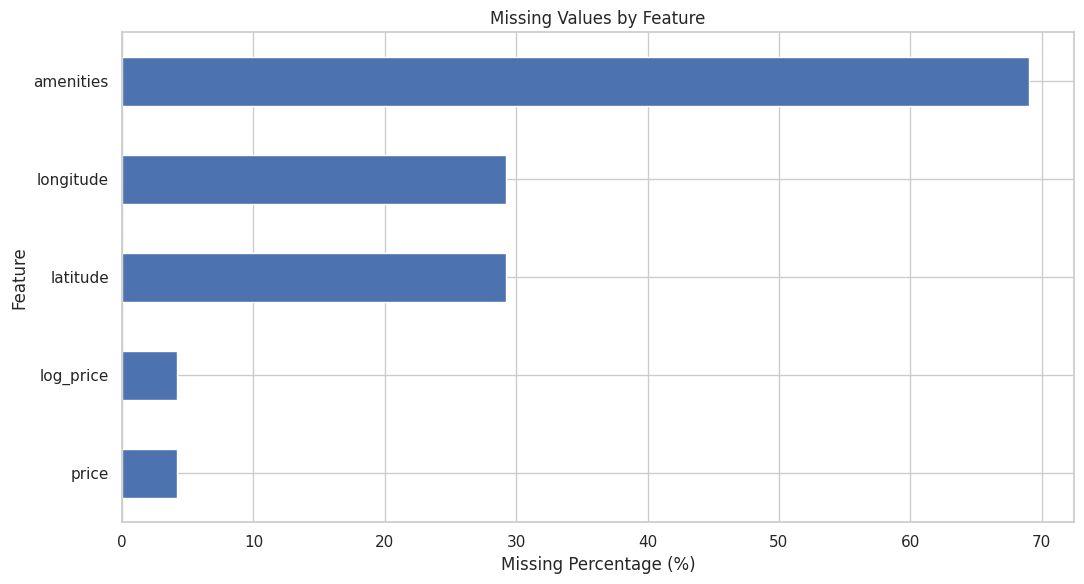

In [ ]:
# Missing-value visualization

if len(missing) > 0:
    plt.figure(figsize=(11, 6))
    missing["Missing Percentage"].sort_values().plot(kind="barh")
    plt.title("Missing Values by Feature")
    plt.xlabel("Missing Percentage (%)")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

In [ ]:
# Preserve a working copy for cleaning

clean_df = df.copy()

# Remove exact duplicate rows.
clean_df = clean_df.drop_duplicates()


clean_df = clean_df.drop_duplicates(
    subset="hotel_id",
    keep="first"
)

print("Shape after duplicate removal:", clean_df.shape)
print("Duplicate hotel IDs remaining:", clean_df["hotel_id"].duplicated().sum())


Shape after duplicate removal: (4551, 31)
Duplicate hotel IDs remaining: 0


In [ ]:
# Numerical missing-value treatment


numeric_columns = [
    "price",
    "log_price",
    "review_count",
    "latitude",
    "longitude",
    "amenity_count"
]

for col in numeric_columns:
    if col in clean_df.columns:
        clean_df[col] = pd.to_numeric(
            clean_df[col], errors="coerce"
        )
        clean_df[col] = clean_df[col].fillna(
            clean_df[col].median()
        )

print("Numerical predictor missing values handled.")


Numerical predictor missing values handled.


In [ ]:
# Categorical/text missing-value treatment

categorical_columns = ["location", "hotel_category"]

for col in categorical_columns:
    if col in clean_df.columns:
        clean_df[col] = clean_df[col].fillna("Unknown")

if "amenities" in clean_df.columns:
    clean_df["amenities"] = clean_df["amenities"].fillna("No amenities listed")

print("Categorical/text missing values handled.")

Categorical/text missing values handled.


In [ ]:
# Amenity indicator columns
amenity_columns = [
    col for col in clean_df.columns
    if col.startswith("amenity_") and col != "amenity_count"
]

# Convert amenity indicators to numeric where necessary.
for col in amenity_columns:
    clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce").fillna(0)

# Keep amenity_count numeric.
if "amenity_count" in clean_df.columns:
    clean_df["amenity_count"] = pd.to_numeric(
        clean_df["amenity_count"], errors="coerce"
    ).fillna(0)

print("Number of individual amenity features:", len(amenity_columns))
print(amenity_columns)

Number of individual amenity features: 15
['amenity_air_conditioning', 'amenity_room_service', 'amenity_full_service_laundry', 'amenity_free_wi_fi', 'amenity_kid_friendly', 'amenity_restaurant', 'amenity_free_breakfast', 'amenity_free_parking', 'amenity_airport_shuttle', 'amenity_accessible', 'amenity_kitchen_in_some_rooms', 'amenity_smoke_free_property', 'amenity_breakfast_($)', 'amenity_bar', 'amenity_parking']


In [ ]:
# Verify missing values after cleaning

remaining_missing = clean_df.isnull().sum()
remaining_missing = remaining_missing[remaining_missing > 0]

if len(remaining_missing) == 0:
    print("No missing values remain in the cleaned dataset.")
else:
    display(remaining_missing.to_frame("Remaining Missing Values"))


No missing values remain in the cleaned dataset.


In [ ]:
# Final target consistency check

expected_success = (clean_df["customer_rating"] >= 4.0).astype(int)
target_mismatches = int(
    (clean_df["success"] != expected_success).sum()
)

print("Target mismatches after cleaning:", target_mismatches)

# This assertion prevents the notebook from continuing with inconsistent labels.
assert target_mismatches == 0, (
    "The success target is inconsistent with customer_rating >= 4.0."
)

print("✓ Every hotel satisfies: success = 1 iff customer_rating >= 4.0.")
print("\nHotels with rating < 4 and success = 1:",
      int(((clean_df["customer_rating"] < 4.0) & (clean_df["success"] == 1)).sum()))
print("Hotels with rating >= 4 and success = 0:",
      int(((clean_df["customer_rating"] >= 4.0) & (clean_df["success"] == 0)).sum()))


Target mismatches after cleaning: 0
✓ Every hotel satisfies: success = 1 iff customer_rating >= 4.0.

Hotels with rating < 4 and success = 1: 0
Hotels with rating >= 4 and success = 0: 0


### Missing-value treatment justification

- Numerical variables are imputed using the median because hotel prices and
  review counts can be skewed and the median is less sensitive to extreme values.
- Missing categorical values are represented as `Unknown` rather than dropping
  potentially useful hotel records.
- Missing amenity descriptions are represented as `No amenities listed`.
- Individual binary amenity indicators are treated as 0 when their value is
  missing, representing absence/not listed for modelling purposes.

## 4.1 Duplicate and Outlier Analysis

Duplicate hotel records are removed using `hotel_id`.

Outliers are identified using the Interquartile Range (IQR) rule. Extreme
values are not automatically deleted because a high hotel price or review
count can represent a genuine hotel rather than a data-entry error.

In [ ]:
outlier_columns = [
    "price",
    "log_price",
    "customer_rating",
    "review_count",
    "latitude",
    "longitude",
    "amenity_count"
]

outlier_summary = []

for col in outlier_columns:
    if col not in clean_df.columns:
        continue

    Q1 = clean_df[col].quantile(0.25)
    Q3 = clean_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    mask = (
        (clean_df[col] < lower_bound) |
        (clean_df[col] > upper_bound)
    )

    count = int(mask.sum())

    outlier_summary.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": count,
        "Outlier Percentage": count / len(clean_df) * 100
    })

outlier_df = pd.DataFrame(outlier_summary)
display(outlier_df.round(2))

,Feature,Q1,Q3,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,price,1649.50,4592.00,-2764.25,9005.75,309,6.79
1,log_price,7.41,8.43,5.87,9.97,66,1.45
2,customer_rating,4.10,5.00,2.75,6.35,55,1.21
3,review_count,147.45,1699.65,-2180.85,4027.95,624,13.71
4,latitude,12.88,24.13,-4.01,41.02,0,0.00
5,longitude,75.78,75.79,75.75,75.82,1087,23.88
6,amenity_count,5.00,14.00,-8.50,27.50,55,1.21


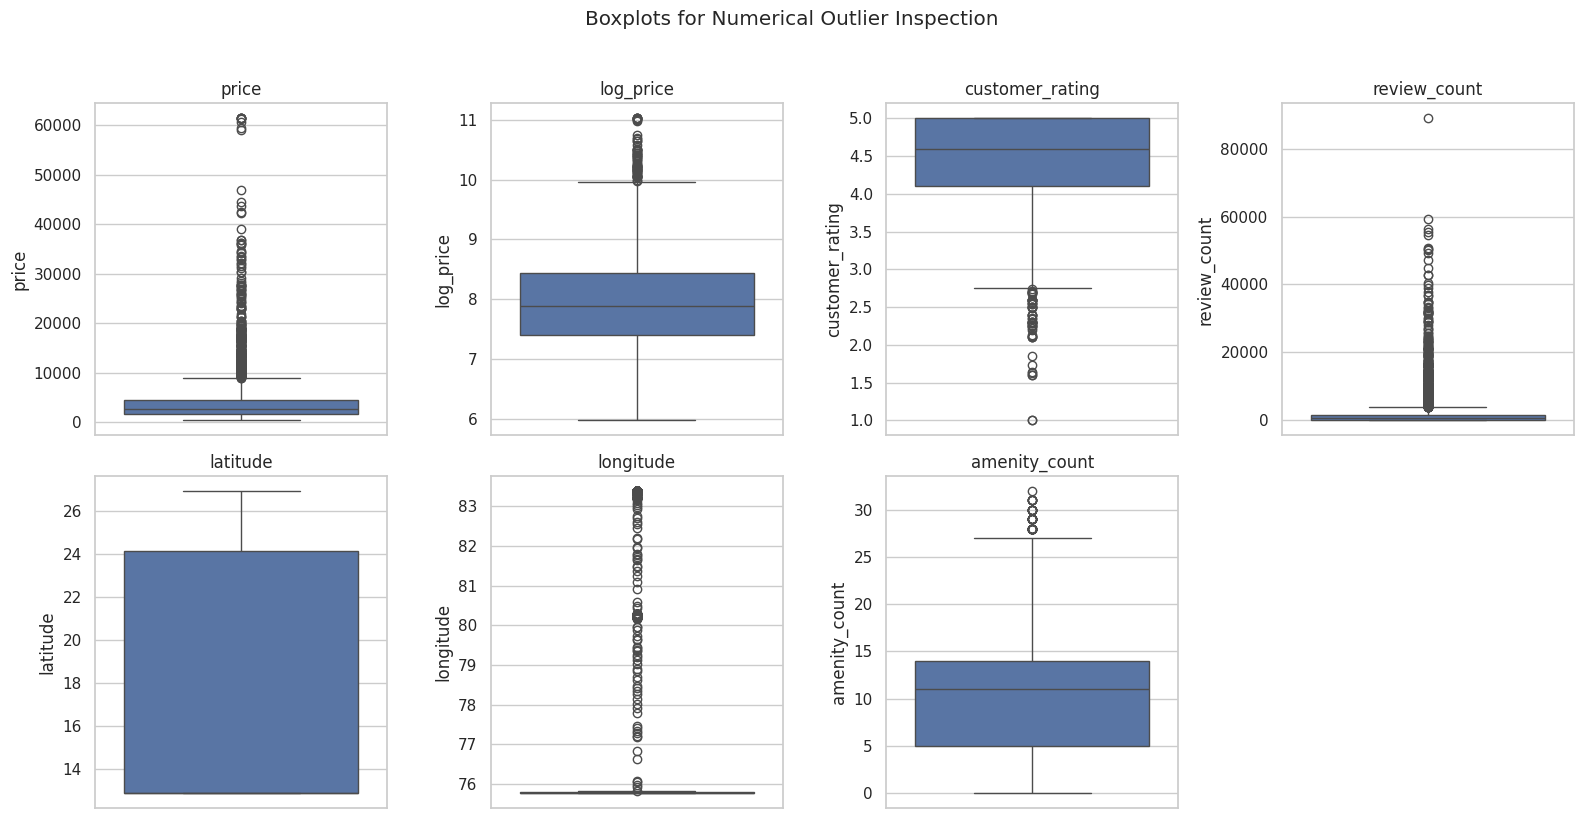

In [ ]:
# Visual inspection of numerical outliers

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(outlier_columns):
    if col in clean_df.columns:
        sns.boxplot(y=clean_df[col], ax=axes[i])
        axes[i].set_title(col)

for j in range(len(outlier_columns), len(axes)):
    axes[j].axis("off")

plt.suptitle("Boxplots for Numerical Outlier Inspection", y=1.02)
plt.tight_layout()
plt.show()

### Outlier treatment decision

The IQR analysis is used to identify unusual observations, but valid extreme
hotel values are retained rather than deleted automatically. This avoids
removing potentially genuine high-priced hotels or hotels with unusually high
review counts.

The effect of skewed numerical variables is handled where appropriate through
log transformation and standardization during modelling.

In [ ]:
# Before vs after cleaning summary

before_cleaning = {
    "Rows": len(df),
    "Columns": df.shape[1],
    "Exact Duplicate Rows": int(df.duplicated().sum()),
    "Duplicate Hotel IDs": int(df["hotel_id"].duplicated().sum()),
    "Missing Values": int(df.isnull().sum().sum())
}

after_cleaning = {
    "Rows": len(clean_df),
    "Columns": clean_df.shape[1],
    "Exact Duplicate Rows": int(clean_df.duplicated().sum()),
    "Duplicate Hotel IDs": int(clean_df["hotel_id"].duplicated().sum()),
    "Missing Values": int(clean_df.isnull().sum().sum())
}

comparison_df = pd.DataFrame(
    [before_cleaning, after_cleaning],
    index=["Before Cleaning", "After Cleaning"]
)

display(comparison_df)

,Rows,Columns,Exact Duplicate Rows,Duplicate Hotel IDs,Missing Values
Before Cleaning,4551,31,0,0,6177
After Cleaning,4551,31,0,0,0


### Encoding and scaling

Categorical variables such as `location` and `hotel_category` are encoded using
One-Hot Encoding during model preprocessing.

Numerical variables are standardized using `StandardScaler`.

These transformations are implemented inside a Scikit-learn pipeline so that
the preprocessing is fitted only on the training data and then consistently
applied to the test data.

# 5. Exploratory Data Analysis and Visualization




Success counts:


,Count
success,
Not Successful,833
Successful,3718



Success percentages:


,Percentage
success,
Not Successful,18.3
Successful,81.7


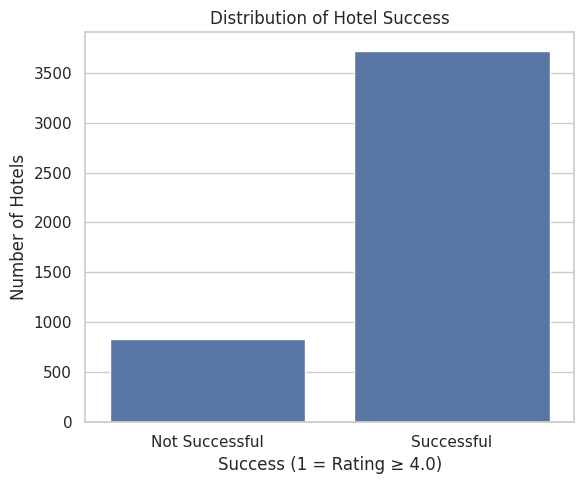

In [ ]:
# Target distribution after applying the 4.0 rating rule

print("Success counts:")
display(
    clean_df["success"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Not Successful", 1: "Successful"})
    .to_frame("Count")
)

print("\nSuccess percentages:")
display(
    clean_df["success"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
    .rename(index={0: "Not Successful", 1: "Successful"})
    .to_frame("Percentage")
)

plt.figure(figsize=(6, 5))
sns.countplot(data=clean_df, x="success")
plt.title("Distribution of Hotel Success")
plt.xlabel("Success (1 = Rating ≥ 4.0)")
plt.ylabel("Number of Hotels")
plt.xticks([0, 1], ["Not Successful", "Successful"])
plt.tight_layout()
plt.show()


data_type
Synthetic    2887
Real         1664
Name: count, dtype: int64


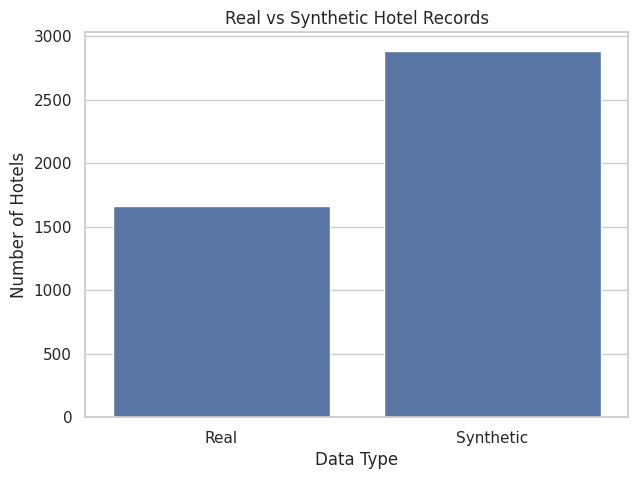

In [ ]:
# Real vs synthetic records

print(clean_df["data_type"].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(data=clean_df, x="data_type")
plt.title("Real vs Synthetic Hotel Records")
plt.xlabel("Data Type")
plt.ylabel("Number of Hotels")
plt.show()

,count,mean,median,min,max
data_type,,,,,
Real,1664,4.13,4.20,1.0,5.0
Synthetic,2887,4.63,4.86,1.6,5.0


,Hotels with Rating < 4,Percentage with Rating < 4
data_type,,
Real,486,29.21
Synthetic,347,12.02


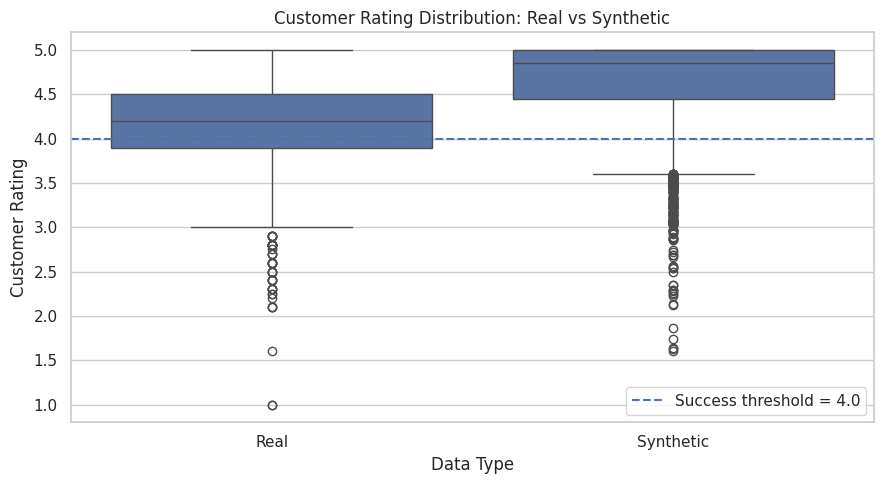

Synthetic hotels with rating < 4 but success = 1: 0


In [ ]:
# Real vs synthetic rating distribution

rating_by_source = (
    clean_df.groupby("data_type")["customer_rating"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(rating_by_source)

below_four_by_source = (
    clean_df.assign(
        below_4=clean_df["customer_rating"] < 4.0
    )
    .groupby("data_type")["below_4"]
    .agg(["sum", "mean"])
)

below_four_by_source["percentage_below_4"] = (
    below_four_by_source["mean"] * 100
).round(2)

display(
    below_four_by_source[["sum", "percentage_below_4"]]
    .rename(columns={
        "sum": "Hotels with Rating < 4",
        "percentage_below_4": "Percentage with Rating < 4"
    })
)

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=clean_df,
    x="data_type",
    y="customer_rating"
)
plt.axhline(4.0, linestyle="--", label="Success threshold = 4.0")
plt.title("Customer Rating Distribution: Real vs Synthetic")
plt.xlabel("Data Type")
plt.ylabel("Customer Rating")
plt.legend()
plt.tight_layout()
plt.show()

# This check directly addresses the synthetic-data concern:
synthetic_incorrect_success = int(
    (
        (clean_df["data_type"] == "Synthetic")
        & (clean_df["customer_rating"] < 4.0)
        & (clean_df["success"] == 1)
    ).sum()
)

print(
    "Synthetic hotels with rating < 4 but success = 1:",
    synthetic_incorrect_success
)
assert synthetic_incorrect_success == 0


success,0,1
data_type,,
Real,29.21,70.79
Synthetic,12.02,87.98


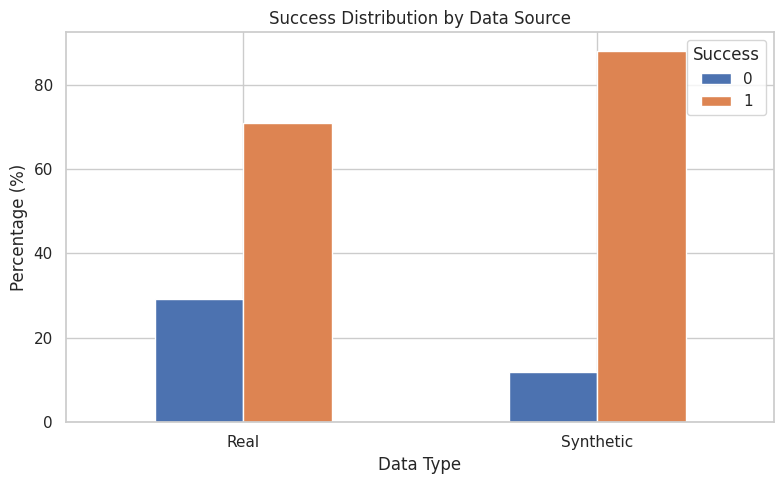

In [ ]:
# Real vs synthetic target distribution

source_success = pd.crosstab(
    clean_df["data_type"],
    clean_df["success"],
    normalize="index"
) * 100

display(source_success.round(2))

source_success.plot(kind="bar", figsize=(8, 5))
plt.title("Success Distribution by Data Source")
plt.xlabel("Data Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Success")
plt.tight_layout()
plt.show()

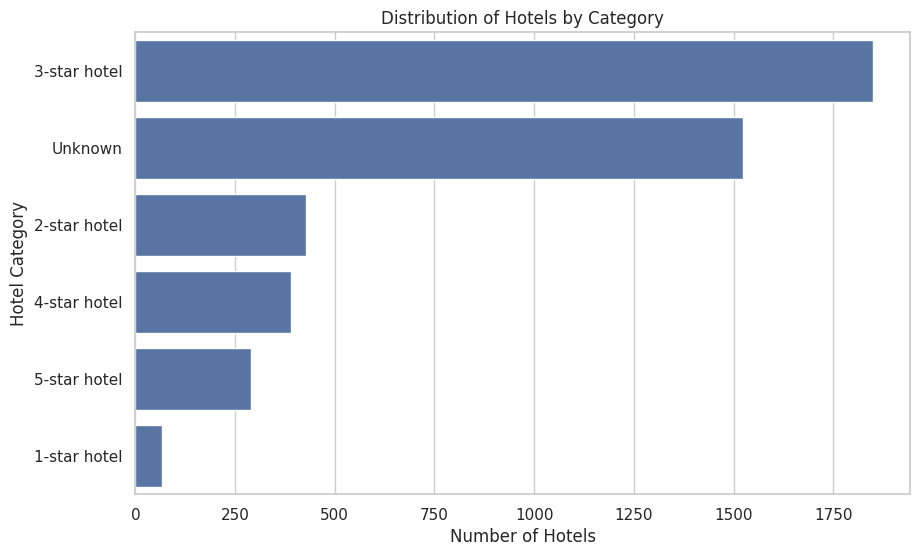

In [ ]:
# Hotel category distribution

plt.figure(figsize=(10, 6))
sns.countplot(
    data=clean_df,
    y="hotel_category",
    order=clean_df["hotel_category"].value_counts().index
)
plt.title("Distribution of Hotels by Category")
plt.xlabel("Number of Hotels")
plt.ylabel("Hotel Category")
plt.show()

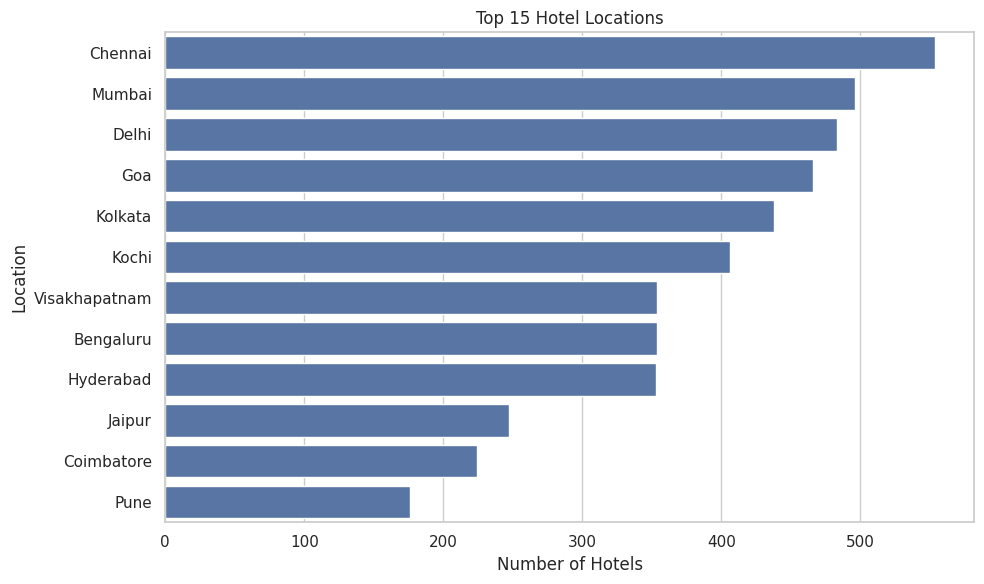

In [ ]:
# Location distribution

location_counts = clean_df["location"].value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=location_counts.values,
    y=location_counts.index
)
plt.title("Top 15 Hotel Locations")
plt.xlabel("Number of Hotels")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

success,0,1
hotel_category,,
1-star hotel,30.30,69.70
2-star hotel,25.64,74.36
3-star hotel,20.91,79.09
4-star hotel,11.00,89.00
5-star hotel,7.96,92.04
Unknown,16.39,83.61


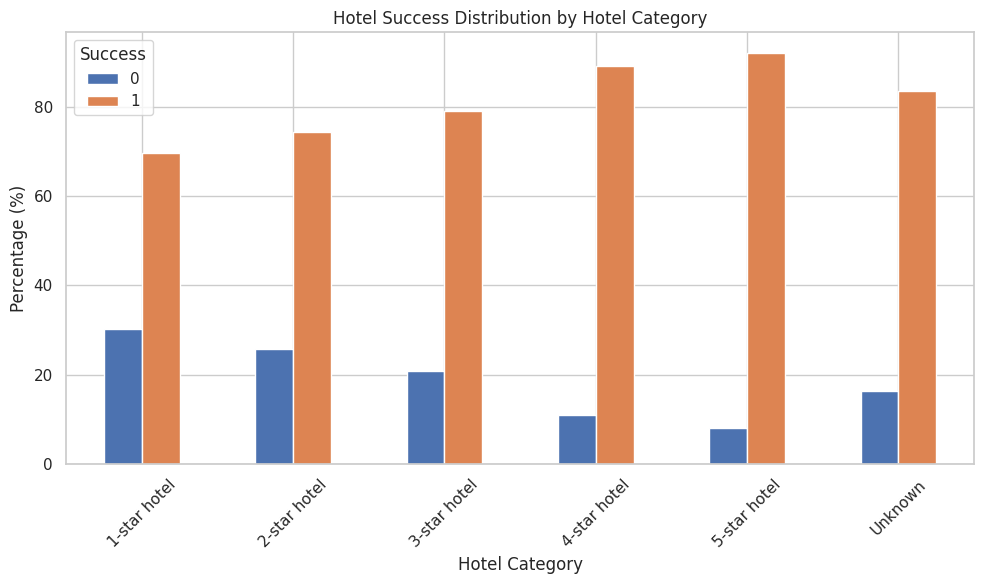

In [ ]:
# Hotel category versus success

category_success = pd.crosstab(
    clean_df["hotel_category"],
    clean_df["success"],
    normalize="index"
) * 100

display(category_success.round(2))

category_success.plot(
    kind="bar",
    figsize=(10, 6)
)
plt.title("Hotel Success Distribution by Hotel Category")
plt.xlabel("Hotel Category")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)
plt.legend(title="Success")
plt.tight_layout()
plt.show()

,Hotels Providing Amenity (%)
amenity_air_conditioning,78.05
amenity_room_service,74.29
amenity_full_service_laundry,70.78
amenity_parking,67.15
amenity_free_wi_fi,62.93
amenity_kid_friendly,52.47
amenity_restaurant,47.86
amenity_free_parking,45.46
amenity_free_breakfast,41.02
amenity_airport_shuttle,40.10


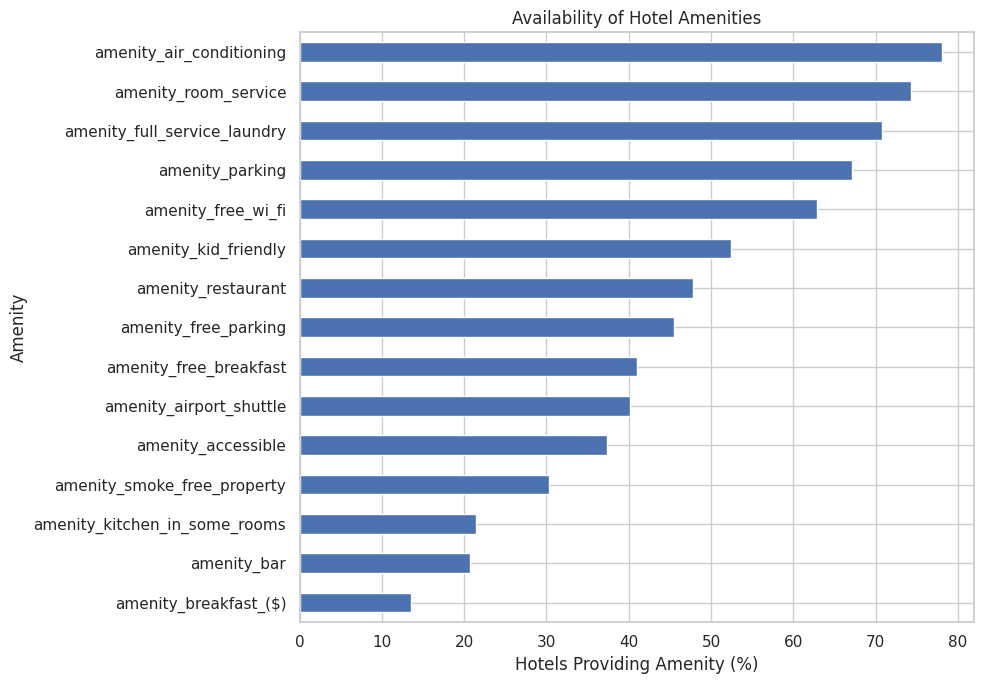

In [ ]:
# Amenity availability

amenity_usage = clean_df[amenity_columns].mean().mul(100).sort_values(ascending=False)

display(amenity_usage.round(2).to_frame("Hotels Providing Amenity (%)"))

plt.figure(figsize=(10, 7))
amenity_usage.sort_values().plot(kind="barh")
plt.title("Availability of Hotel Amenities")
plt.xlabel("Hotels Providing Amenity (%)")
plt.ylabel("Amenity")
plt.tight_layout()
plt.show()

In [ ]:
# Amenities and observed success-rate differences

amenity_success = {}

for col in amenity_columns:
    with_amenity = clean_df.loc[
        clean_df[col] == 1, "success"
    ].mean() * 100

    without_amenity = clean_df.loc[
        clean_df[col] == 0, "success"
    ].mean() * 100

    amenity_success[col] = {
        "With Amenity (%)": with_amenity,
        "Without Amenity (%)": without_amenity,
        "Difference (%)": with_amenity - without_amenity
    }

amenity_success_df = pd.DataFrame(amenity_success).T.sort_values(
    "Difference (%)", ascending=False
)

display(amenity_success_df.round(2))

,With Amenity (%),Without Amenity (%),Difference (%)
amenity_bar,90.86,79.31,11.55
amenity_free_parking,86.66,77.56,9.10
amenity_accessible,86.87,78.62,8.25
amenity_free_wi_fi,84.57,76.82,7.74
amenity_parking,84.16,76.66,7.51
amenity_breakfast_($),87.32,80.82,6.50
amenity_airport_shuttle,84.16,80.04,4.12
amenity_smoke_free_property,84.36,80.54,3.82
amenity_restaurant,83.47,80.07,3.40
amenity_full_service_laundry,82.52,79.70,2.82


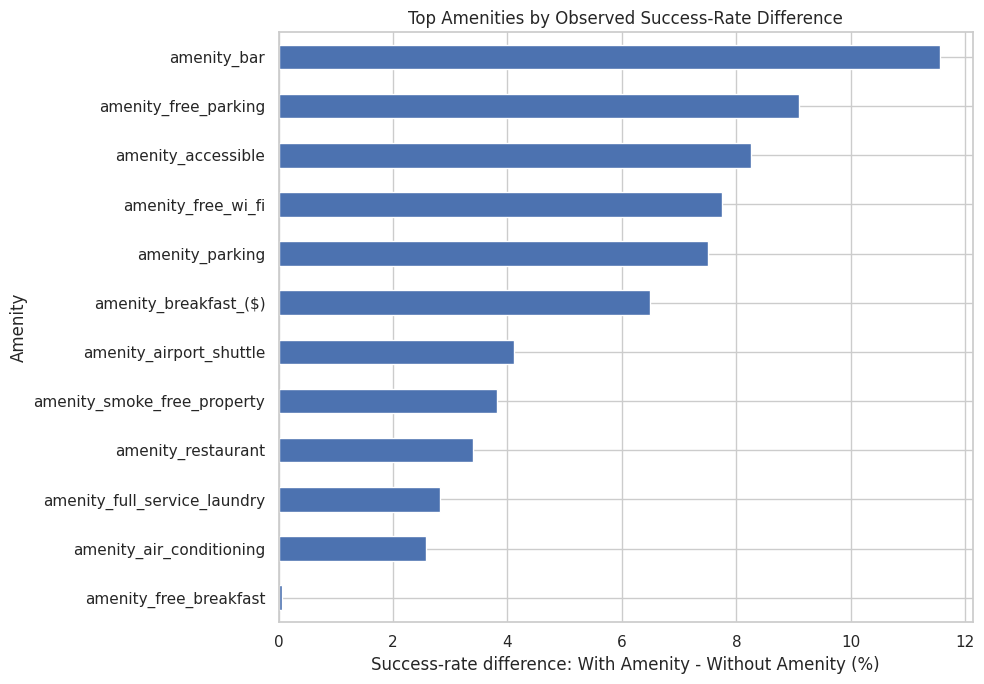

In [ ]:
# Top amenities by observed success-rate difference

top_amenity_effects = amenity_success_df.copy()

plt.figure(figsize=(10, 7))
top_amenity_effects["Difference (%)"].head(12).sort_values().plot(
    kind="barh"
)
plt.title("Top Amenities by Observed Success-Rate Difference")
plt.xlabel("Success-rate difference: With Amenity - Without Amenity (%)")
plt.ylabel("Amenity")
plt.tight_layout()
plt.show()

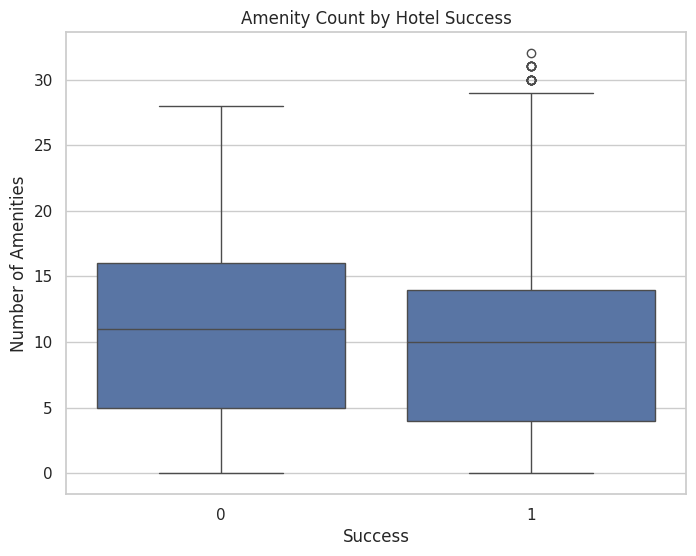

,mean,median,min,max
success,,,,
0,10.81,11.0,0,28
1,10.43,10.0,0,32


In [ ]:
# Amenity count versus success

plt.figure(figsize=(8, 6))
sns.boxplot(
    data=clean_df,
    x="success",
    y="amenity_count"
)
plt.title("Amenity Count by Hotel Success")
plt.xlabel("Success")
plt.ylabel("Number of Amenities")
plt.show()

display(
    clean_df.groupby("success")["amenity_count"]
    .agg(["mean", "median", "min", "max"])
    .round(2)
)

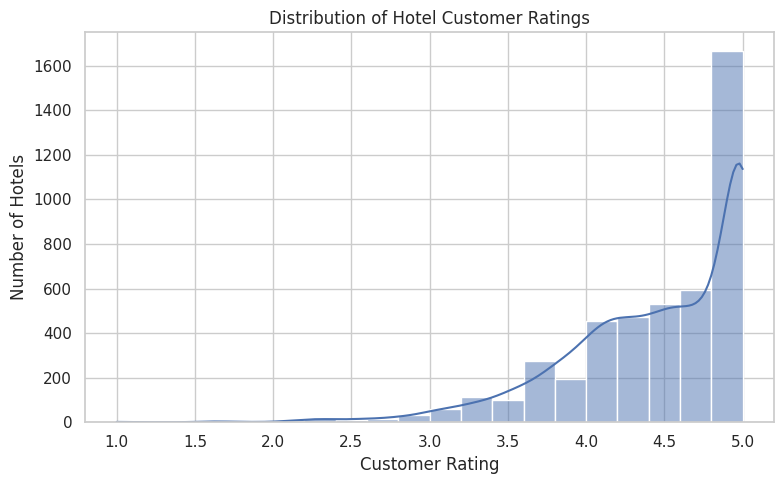

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["customer_rating"].dropna(),
    bins=20,
    kde=True
)

plt.title("Distribution of Hotel Customer Ratings")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Hotels")

plt.tight_layout()
plt.show()

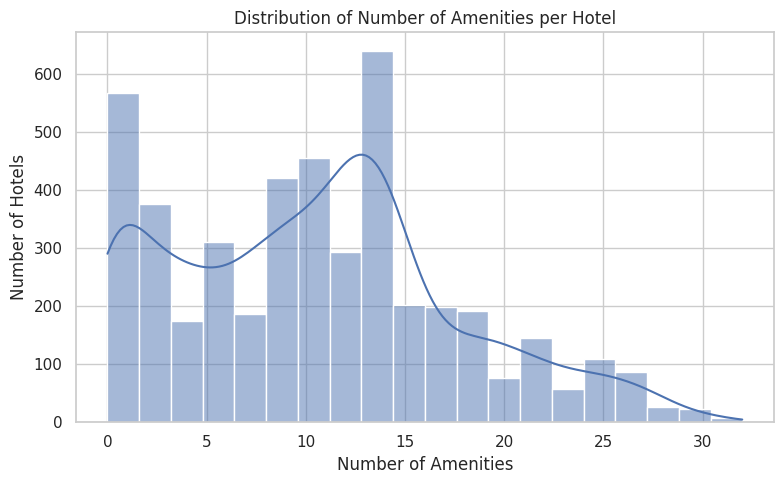

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["amenity_count"].dropna(),
    bins=20,
    kde=True
)

plt.title("Distribution of Number of Amenities per Hotel")
plt.xlabel("Number of Amenities")
plt.ylabel("Number of Hotels")

plt.tight_layout()
plt.show()

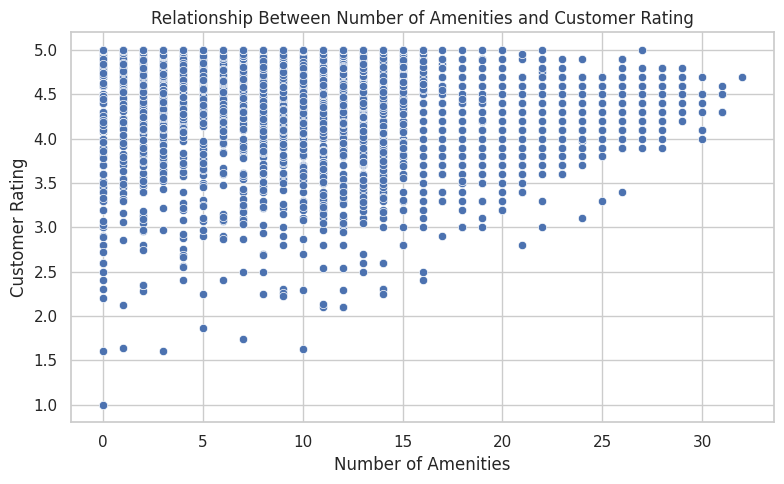

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="amenity_count",
    y="customer_rating"
)

plt.title(
    "Relationship Between Number of Amenities and Customer Rating"
)

plt.xlabel("Number of Amenities")
plt.ylabel("Customer Rating")

plt.tight_layout()
plt.show()

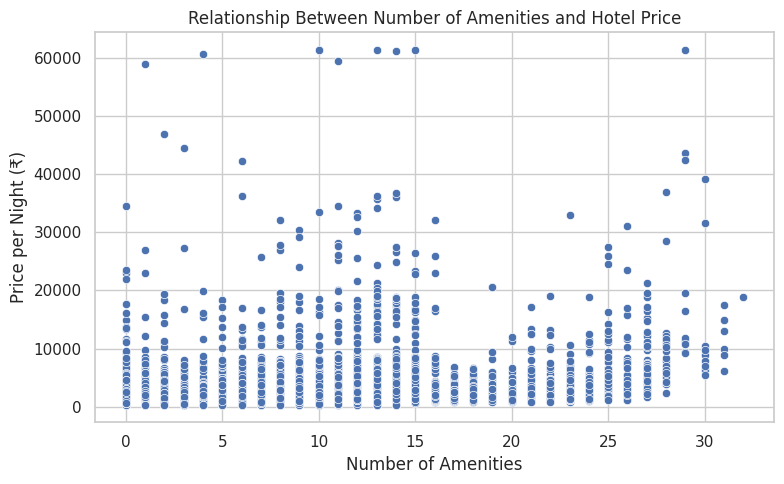

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="amenity_count",
    y="price"
)

plt.title(
    "Relationship Between Number of Amenities and Hotel Price"
)

plt.xlabel("Number of Amenities")
plt.ylabel("Price per Night (₹)")

plt.tight_layout()
plt.show()

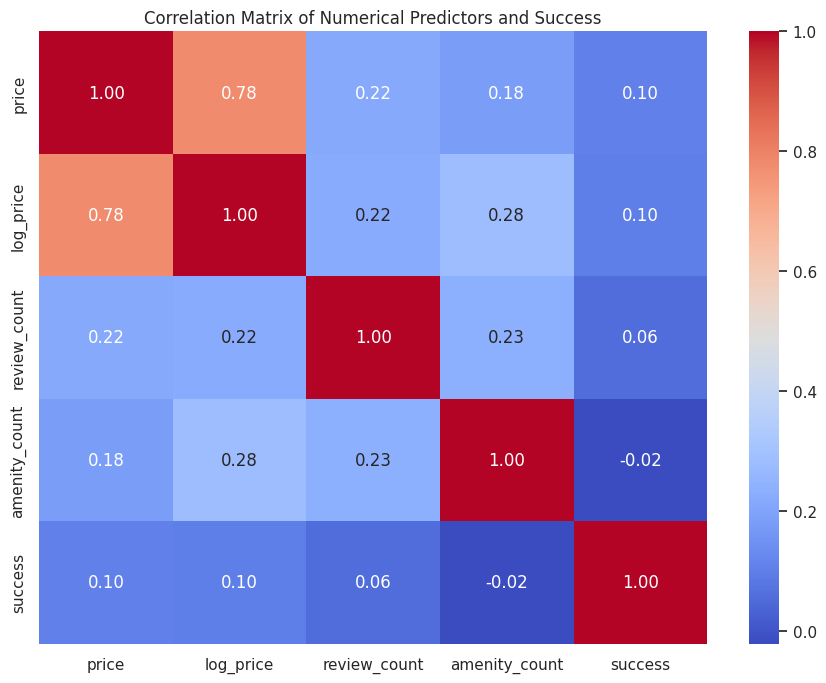

In [ ]:
# Numerical correlation analysis

# customer_rating is excluded from this correlation matrix because success
# is directly defined from customer_rating >= 4.0. Including both would create
# a mechanically induced relationship rather than an independent predictor.
correlation_columns = [
    col for col in [
        "price",
        "log_price",
        "review_count",
        "amenity_count",
        "success"
    ]
    if col in clean_df.columns
]

correlation = clean_df[correlation_columns].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Matrix of Numerical Predictors and Success")
plt.tight_layout()
plt.show()


# 6. Feature Engineering and Dimensionality Reduction

Feature engineering converts hotel variables into representations suitable for
analysis and predictive modelling.

### Features used/verified

- `log_price`: log-transformed hotel price.
- `amenity_count`: total number of amenities.
- Individual `amenity_*` indicators: binary variables representing specific facilities.
- One-hot encoded `location` and `hotel_category` during model preprocessing.

### Why these methods?

Hotel price can be right-skewed, so a log transformation reduces the influence
of very large values. Individual amenity indicators retain information about
specific facilities, while `amenity_count` provides a compact summary.

The existing `log_price` is verified/recalculated from `price` so that it is
consistent with the cleaned dataset.


In [ ]:
# Verify/create the log-price feature

model_df = clean_df.copy()

model_df["log_price"] = np.log1p(model_df["price"])

print("Verified/recalculated feature: log_price = log(1 + price)")
display(
    model_df[["price", "log_price", "amenity_count"]].head()
)


Verified/recalculated feature: log_price = log(1 + price)


,price,log_price,amenity_count
0,2650.5,7.882881,29
1,7961.0,8.982436,27
2,15306.0,9.636066,27
3,33024.0,10.405020,23
4,6987.0,8.851950,23


In [ ]:
# PCA using individual amenity indicators only.
# amenity_count is excluded because it is an aggregate feature.

pca_amenity_columns = [
    col for col in model_df.columns
    if col.startswith("amenity_") and col != "amenity_count"
]

amenity_matrix = model_df[pca_amenity_columns]

scaler_pca = StandardScaler()
amenity_scaled = scaler_pca.fit_transform(amenity_matrix)

pca = PCA(n_components=2)
pca_result = pca.fit_transform(amenity_scaled)

model_df["PCA1_new"] = pca_result[:, 0]
model_df["PCA2_new"] = pca_result[:, 1]

explained_variance = pca.explained_variance_ratio_

print("Original number of amenity features:", len(pca_amenity_columns))
print("Number of PCA components:", 2)
print("PC1 explained variance:", round(explained_variance[0] * 100, 2), "%")
print("PC2 explained variance:", round(explained_variance[1] * 100, 2), "%")
print(
    "Total variance retained:",
    round(explained_variance.sum() * 100, 2),
    "%"
)

Original number of amenity features: 15
Number of PCA components: 2
PC1 explained variance: 40.38 %
PC2 explained variance: 7.87 %
Total variance retained: 48.25 %


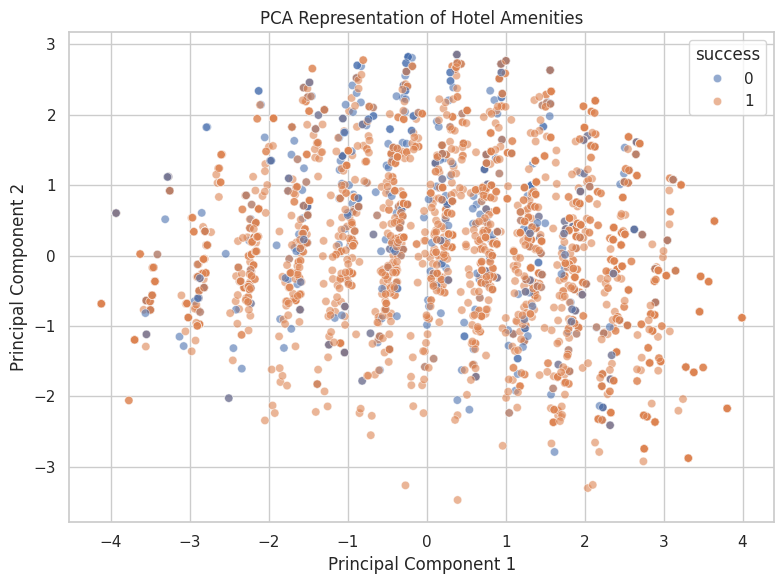

In [ ]:
# PCA visualization

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=model_df,
    x="PCA1_new",
    y="PCA2_new",
    hue="success",
    alpha=0.6
)

plt.title("PCA Representation of Hotel Amenities")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

### Effect of PCA

PCA reduces the individual amenity feature space to two principal components
for visualization.



# 7. Predictive Model Development

### Prediction task

This is a **binary classification** problem.

- `success = 0` → customer rating < 4.0
- `success = 1` → customer rating ≥ 4.0

### Models

Three classification algorithms are implemented:

1. **Logistic Regression** – a linear baseline.
2. **Decision Tree** – captures non-linear decision rules.
3. **Random Forest** – combines multiple decision trees.

### Data split

The cleaned dataset is split into **80% training and 20% testing data** using
stratified sampling.




In [ ]:
# Define features and target with explicit leakage prevention

y = model_df["success"].astype(int)

# Individual amenity features
amenity_columns = [
    col for col in model_df.columns
    if col.startswith("amenity_")
    and col != "amenity_count"
]

# Numerical predictors
numeric_features = [
    "price",
    "log_price",
    "review_count",
    "amenity_count"
] + amenity_columns

# Categorical predictors
categorical_features = [
    "location",
    "hotel_category"
]

numeric_features = [
    col for col in numeric_features
    if col in model_df.columns
]

categorical_features = [
    col for col in categorical_features
    if col in model_df.columns
]

# the feature matrix.
X = model_df[
    numeric_features + categorical_features
].copy()

# safety checks against target leakage.
for forbidden in [
    "success",
    "customer_rating",
    "hotel_id",
    "hotel_name",
    "amenities",
    "PCA1",
    "PCA2",
    "PCA1_new",
    "PCA2_new"
]:
    assert forbidden not in X.columns, (
        f"Leakage/identifier column found in model features: {forbidden}"
    )

assert not X.columns.duplicated().any()

print("Number of predictors:", X.shape[1])
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nDuplicate predictor names:")
print(X.columns[X.columns.duplicated()].tolist())

print("\n✓ Customer rating is excluded from X because it defines success.")
print("✓ Success itself is excluded from X.")


Number of predictors: 21
Feature matrix shape: (4551, 21)
Target shape: (4551,)

Numerical features:
['price', 'log_price', 'review_count', 'amenity_count', 'amenity_air_conditioning', 'amenity_room_service', 'amenity_full_service_laundry', 'amenity_free_wi_fi', 'amenity_kid_friendly', 'amenity_restaurant', 'amenity_free_breakfast', 'amenity_free_parking', 'amenity_airport_shuttle', 'amenity_accessible', 'amenity_kitchen_in_some_rooms', 'amenity_smoke_free_property', 'amenity_breakfast_($)', 'amenity_bar', 'amenity_parking']

Categorical features:
['location', 'hotel_category']

Duplicate predictor names:
[]

✓ Customer rating is excluded from X because it defines success.
✓ Success itself is excluded from X.


In [ ]:
# Train-test split: 80/20 stratified split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).mul(100).round(2).to_frame("Percentage"))

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).mul(100).round(2).to_frame("Percentage"))

Training data: (3640, 21)
Testing data: (911, 21)

Training target distribution:


,Percentage
success,
1,81.7
0,18.3



Testing target distribution:


,Percentage
success,
1,81.67
0,18.33


## 7.1 Encoding and Scaling Pipeline

Categorical variables are converted using `OneHotEncoder`, while numerical
variables are standardized using `StandardScaler`.

Using a `ColumnTransformer` and `Pipeline` prevents data leakage from the test
set during preprocessing.

In [ ]:
# Improved preprocessing pipeline

from sklearn.impute import SimpleImputer

# Numerical preprocessing:
# 1. Fill any missing numerical values using the median
# 2. Standardize numerical variables

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Categorical preprocessing:
# 1. Fill missing categories using the most frequent category
# 2. Convert categories into one-hot encoded variables

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

# Combine numerical and categorical preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Improved preprocessing pipeline created.")

Improved preprocessing pipeline created.


In [ ]:
# Logistic Regression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(max_iter=1000)
        )
    ]
)

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)

print("Logistic Regression")
print(
    classification_report(
        y_test,
        logistic_pred,
        zero_division=0
    )
)

Logistic Regression
              precision    recall  f1-score   support

           0       0.57      0.10      0.17       167
           1       0.83      0.98      0.90       744

    accuracy                           0.82       911
   macro avg       0.70      0.54      0.54       911
weighted avg       0.78      0.82      0.77       911



In [ ]:
# Decision Tree

decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=5,
                random_state=42
            )
        )
    ]
)

decision_tree_model.fit(X_train, y_train)

tree_pred = decision_tree_model.predict(X_test)

print("Decision Tree")
print(
    classification_report(
        y_test,
        tree_pred,
        zero_division=0
    )
)

Decision Tree
              precision    recall  f1-score   support

           0       0.57      0.19      0.28       167
           1       0.84      0.97      0.90       744

    accuracy                           0.83       911
   macro avg       0.71      0.58      0.59       911
weighted avg       0.79      0.83      0.79       911



In [ ]:
# Random Forest

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=10,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

rf_pred = random_forest_model.predict(X_test)

print("Random Forest")
print(
    classification_report(
        y_test,
        rf_pred,
        zero_division=0
    )
)

Random Forest
              precision    recall  f1-score   support

           0       0.72      0.13      0.21       167
           1       0.83      0.99      0.91       744

    accuracy                           0.83       911
   macro avg       0.78      0.56      0.56       911
weighted avg       0.81      0.83      0.78       911



### Model settings

| Model | Baseline settings |
|---|---|
| Logistic Regression | `max_iter=1000` |
| Decision Tree | `max_depth=5`, `random_state=42` |
| Random Forest | `n_estimators=200`, `max_depth=10`, `random_state=42`, `n_jobs=-1` |

The baseline models provide a reproducible comparison. Hyperparameter tuning is
performed later using five-fold cross-validation and Macro F1-score.


# 8. Model Evaluation and Result Interpretation




In [ ]:
# Target class balance

class_distribution = pd.DataFrame({
    "Count": clean_df["success"].value_counts(),
    "Percentage": clean_df["success"].value_counts(normalize=True).mul(100).round(2)
})

display(class_distribution)

,Count,Percentage
success,,
1,3718,81.7
0,833,18.3


### Class imbalance interpretation

The target distribution should be checked before interpreting model accuracy.
If one class is much more common than the other, a model can achieve relatively
high accuracy while performing poorly on the less common class.

For this reason, the evaluation considers precision, recall, F1-score,
Macro F1, balanced accuracy and confusion matrices in addition to accuracy.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

# Model predictions
models = {
    "Logistic Regression": logistic_pred,
    "Decision Tree": tree_pred,
    "Random Forest": rf_pred
}

results = []

for name, predictions in models.items():

    results.append({
        "Model": name,

        # Standard metrics
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),

        # Imbalance-aware metrics
        "Macro Precision": precision_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        )
    })

# Create final table
results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy
0,Logistic Regression,0.8211,0.8297,0.9825,0.8997,0.6982,0.5422,0.5361,0.5422
1,Decision Tree,0.8255,0.8413,0.9691,0.9007,0.7077,0.5774,0.5906,0.5774
2,Random Forest,0.8310,0.8345,0.9892,0.9053,0.7793,0.5575,0.5598,0.5575


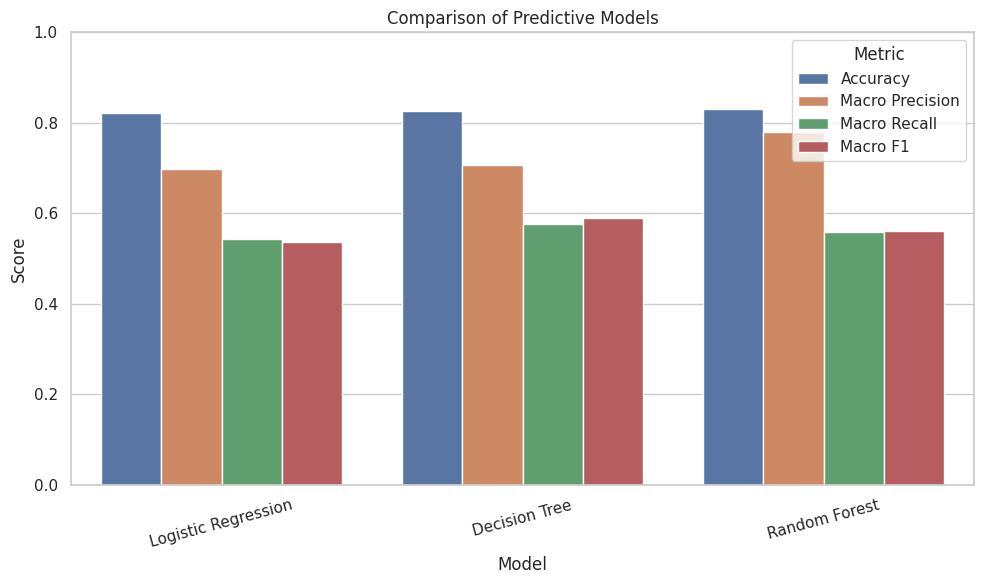

In [ ]:
# Model comparison visualization

results_melted = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Comparison of Predictive Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

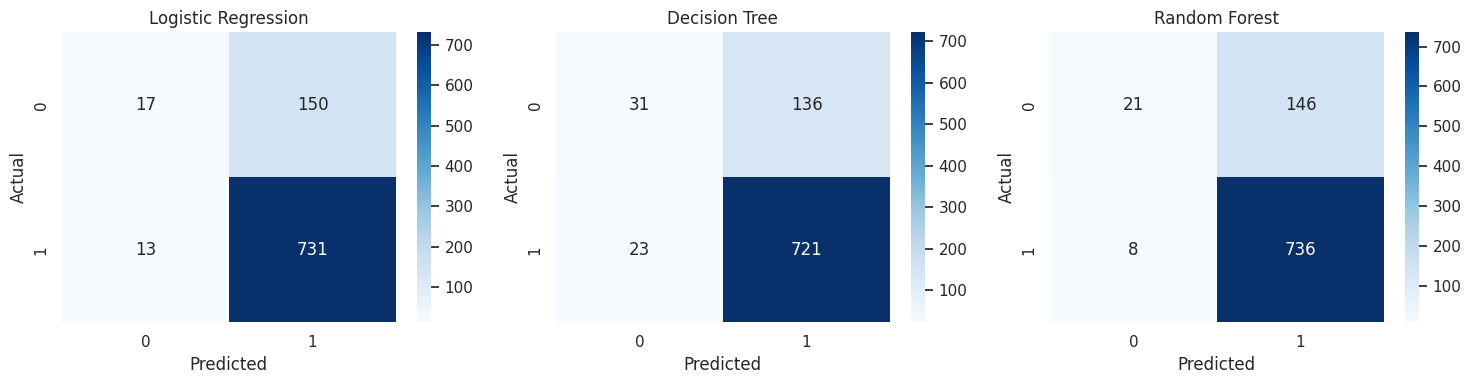

In [ ]:
# Confusion matrices

predictions = [
    ("Logistic Regression", logistic_pred),
    ("Decision Tree", tree_pred),
    ("Random Forest", rf_pred)
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

for ax, (name, pred) in zip(axes, predictions):

    cm = confusion_matrix(y_test, pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
# ROC-AUC comparison

model_probabilities = {
    "Logistic Regression": logistic_model.predict_proba(X_test)[:, 1],
    "Decision Tree": decision_tree_model.predict_proba(X_test)[:, 1],
    "Random Forest": random_forest_model.predict_proba(X_test)[:, 1]
}

roc_results = []

for name, probabilities in model_probabilities.items():
    auc = roc_auc_score(y_test, probabilities)

    roc_results.append({
        "Model": name,
        "ROC-AUC": auc
    })

roc_df = pd.DataFrame(roc_results)

display(roc_df.round(4))

,Model,ROC-AUC
0,Logistic Regression,0.6987
1,Decision Tree,0.6773
2,Random Forest,0.7029


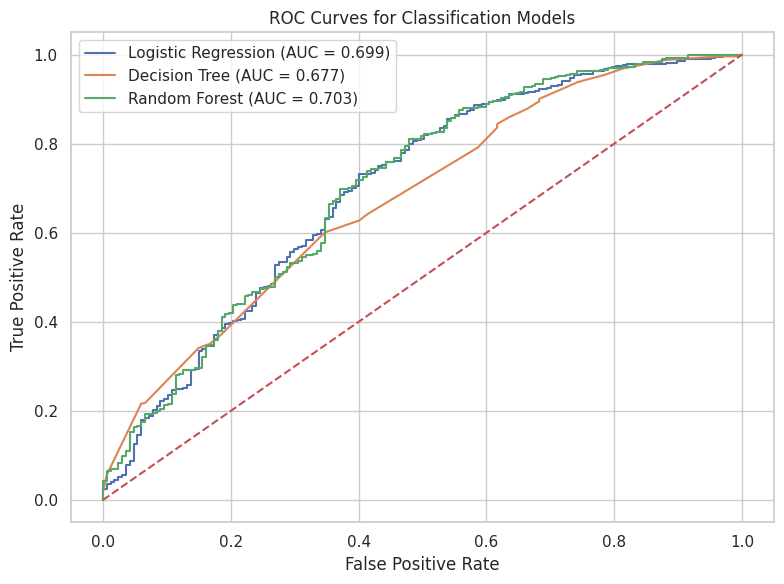

In [ ]:
# ROC curves

plt.figure(figsize=(8, 6))

for name, probabilities in model_probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Classification Models")
plt.legend()
plt.tight_layout()
plt.show()

# 9. Feature Importance and Interpretation

Random Forest feature importance is used to identify which transformed
predictors contribute most to the model's classification decisions.

Feature importance describes the model's use of a feature; it does not prove
that the feature causes hotel success.

In [ ]:
# Random Forest feature importance

feature_names = (
    random_forest_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    random_forest_model
    .named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    "Importance",
    ascending=False
)

display(importance_df.head(20).round(4))

,Feature,Importance
0,num__price,0.1394
1,num__log_price,0.1316
2,num__review_count,0.1266
3,num__amenity_count,0.1212
11,num__amenity_free_parking,0.0315
7,num__amenity_free_wi_fi,0.0300
8,num__amenity_kid_friendly,0.0257
13,num__amenity_accessible,0.0238
36,cat__hotel_category_Unknown,0.0213
33,cat__hotel_category_3-star hotel,0.0211


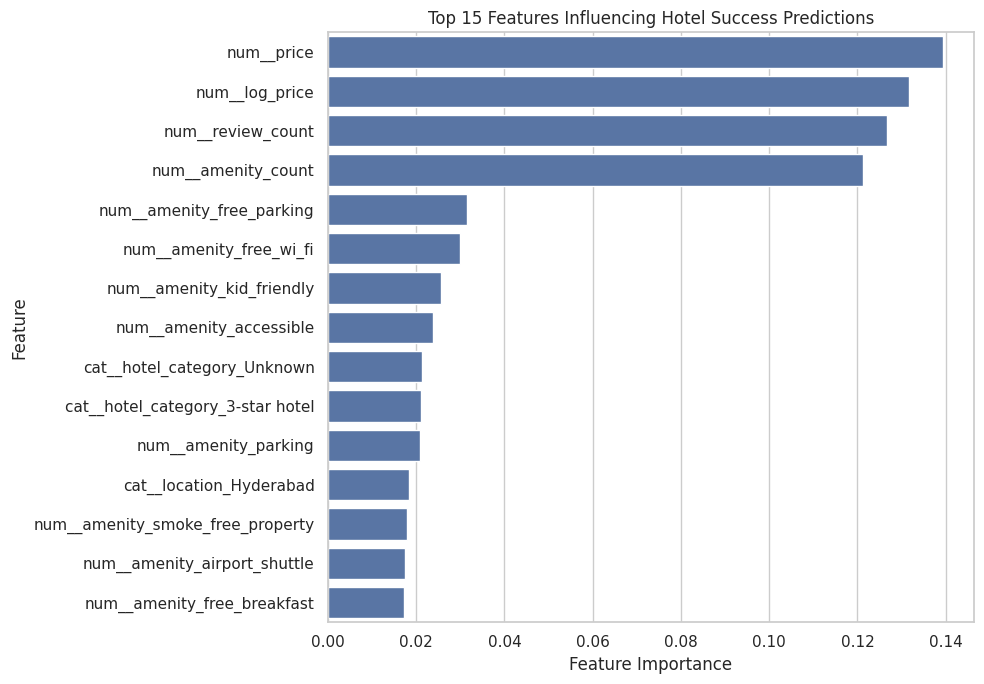

In [ ]:
# Top 15 feature importance visualization

top_features = importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Influencing Hotel Success Predictions")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [ ]:
logistic_model_balanced = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced"
            )
        )
    ]
)

logistic_model_balanced.fit(X_train, y_train)

logistic_balanced_pred = logistic_model_balanced.predict(X_test)

print(classification_report(
    y_test,
    logistic_balanced_pred
))

              precision    recall  f1-score   support

           0       0.32      0.62      0.42       167
           1       0.89      0.71      0.79       744

    accuracy                           0.69       911
   macro avg       0.61      0.66      0.61       911
weighted avg       0.79      0.69      0.72       911



In [ ]:
decision_tree_balanced = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=5,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

decision_tree_balanced.fit(X_train, y_train)

tree_balanced_pred = decision_tree_balanced.predict(X_test)

print(classification_report(
    y_test,
    tree_balanced_pred
))

              precision    recall  f1-score   support

           0       0.35      0.37      0.36       167
           1       0.86      0.85      0.85       744

    accuracy                           0.76       911
   macro avg       0.60      0.61      0.60       911
weighted avg       0.76      0.76      0.76       911



In [ ]:
random_forest_balanced = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=10,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest_balanced.fit(X_train, y_train)

rf_balanced_pred = random_forest_balanced.predict(X_test)

print(classification_report(
    y_test,
    rf_balanced_pred
))

              precision    recall  f1-score   support

           0       0.50      0.34      0.40       167
           1       0.86      0.92      0.89       744

    accuracy                           0.82       911
   macro avg       0.68      0.63      0.65       911
weighted avg       0.79      0.82      0.80       911



In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression - Original",
        "Logistic Regression - Balanced",
        "Decision Tree - Original",
        "Decision Tree - Balanced",
        "Random Forest - Original",
        "Random Forest - Balanced"
    ],

    "F1 Score - Class 0": [
        f1_score(y_test, logistic_pred, pos_label=0),
        f1_score(y_test, logistic_balanced_pred, pos_label=0),
        f1_score(y_test, tree_pred, pos_label=0),
        f1_score(y_test, tree_balanced_pred, pos_label=0),
        f1_score(y_test, rf_pred, pos_label=0),
        f1_score(y_test, rf_balanced_pred, pos_label=0)
    ],

    "Recall - Class 0": [
        recall_score(y_test, logistic_pred, pos_label=0),
        recall_score(y_test, logistic_balanced_pred, pos_label=0),
        recall_score(y_test, tree_pred, pos_label=0),
        recall_score(y_test, tree_balanced_pred, pos_label=0),
        recall_score(y_test, rf_pred, pos_label=0),
        recall_score(y_test, rf_balanced_pred, pos_label=0)
    ]
})

display(comparison.round(3))

,Model,F1 Score - Class 0,Recall - Class 0
0,Logistic Regression - Original,0.173,0.102
1,Logistic Regression - Balanced,0.422,0.617
2,Decision Tree - Original,0.281,0.186
3,Decision Tree - Balanced,0.358,0.365
4,Random Forest - Original,0.214,0.126
5,Random Forest - Balanced,0.400,0.335


In [ ]:
from sklearn.model_selection import GridSearchCV

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000
            )
        )
    ]
)

logistic_params = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}

logistic_grid = GridSearchCV(
    logistic_pipeline,
    logistic_params,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)

print("Best parameters:")
print(logistic_grid.best_params_)

print("Best CV F1-macro:")
print(logistic_grid.best_score_)

Best parameters:
{'classifier__C': 10, 'classifier__class_weight': 'balanced'}
Best CV F1-macro:
0.5806295861661683


In [ ]:
tree_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ]
)

tree_params = {
    "classifier__max_depth": [3, 5, 7, 10, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__class_weight": [None, "balanced"]
}

tree_grid = GridSearchCV(
    tree_pipeline,
    tree_params,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

tree_grid.fit(X_train, y_train)

print("Best parameters:")
print(tree_grid.best_params_)

print("Best CV F1-macro:")
print(tree_grid.best_score_)

Best parameters:
{'classifier__class_weight': None, 'classifier__max_depth': 7, 'classifier__min_samples_split': 10}
Best CV F1-macro:
0.6120213982410533


In [ ]:
# Improved Random Forest hyperparameter tuning

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_params = {
    "classifier__n_estimators": [200, 300],
    "classifier__max_depth": [8, 10, 12],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2],
    "classifier__class_weight": [
        None,
        "balanced",
        {0: 1.5, 1: 1},
        {0: 2, 1: 1},
        {0: 2.5, 1: 1},
        {0: 3, 1: 1}
    ]
}

rf_grid = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print(
    "Best 5-Fold CV Macro F1:",
    round(rf_grid.best_score_, 4)
)

Fitting 5 folds for each of 144 candidates, totalling 720 fits
Best Random Forest parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 300}
Best 5-Fold CV Macro F1: 0.6693


In [ ]:
tuned_models = {
    "Tuned Logistic Regression": logistic_grid.best_estimator_,
    "Tuned Decision Tree": tree_grid.best_estimator_,
    "Tuned Random Forest": rf_grid.best_estimator_
}

tuned_results = []

for name, model in tuned_models.items():

    predictions = model.predict(X_test)

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test,
            predictions,
            average="weighted"
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            average="weighted"
        ),
        "F1 Macro": f1_score(
            y_test,
            predictions,
            average="macro"
        ),
        "F1 Weighted": f1_score(
            y_test,
            predictions,
            average="weighted"
        )
    })

tuned_results_df = pd.DataFrame(tuned_results)

display(tuned_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Macro,F1 Weighted
0,Tuned Logistic Regression,0.6894,0.7866,0.6894,0.6045,0.7205
1,Tuned Decision Tree,0.8035,0.7618,0.8035,0.5750,0.7724
2,Tuned Random Forest,0.8134,0.7976,0.8134,0.6571,0.8037


In [ ]:
from sklearn.model_selection import cross_val_score

cv_results = []

for name, model in tuned_models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="f1_macro",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean CV F1-Macro": scores.mean(),
        "Std CV F1-Macro": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))

,Model,Mean CV F1-Macro,Std CV F1-Macro
0,Tuned Logistic Regression,0.5806,0.0147
1,Tuned Decision Tree,0.6120,0.0302
2,Tuned Random Forest,0.6693,0.0206


In [ ]:
from sklearn.metrics import balanced_accuracy_score

final_results = []

for name, model in tuned_models.items():

    pred = model.predict(X_test)

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred),
        "Macro Precision": precision_score(
            y_test, pred, average="macro"
        ),
        "Macro Recall": recall_score(
            y_test, pred, average="macro"
        ),
        "Macro F1": f1_score(
            y_test, pred, average="macro"
        ),
        "Weighted F1": f1_score(
            y_test, pred, average="weighted"
        )
    })

final_results_df = pd.DataFrame(final_results)

display(final_results_df.round(4))

,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Tuned Logistic Regression,0.6894,0.6612,0.6056,0.6612,0.6045,0.7205
1,Tuned Decision Tree,0.8035,0.5662,0.6297,0.5662,0.5750,0.7724
2,Tuned Random Forest,0.8134,0.6443,0.6777,0.6443,0.6571,0.8037


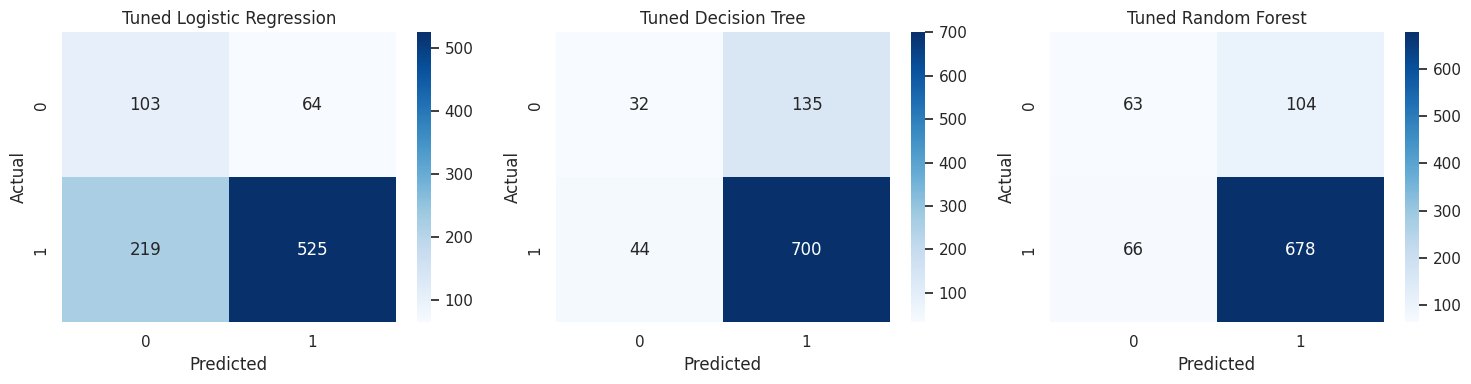

In [ ]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

for ax, (name, model) in zip(
    axes,
    tuned_models.items()
):

    pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        pred
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
# Final dataset and modelling sanity checks

expected_success = (clean_df["customer_rating"] >= 4.0).astype(int)

print("========== FINAL SANITY CHECK ==========")
print("Original imported dataset shape:", raw_df.shape)
print("Working dataset shape after target validation:", df.shape)
print("Cleaned dataset shape:", clean_df.shape)
print("Final modelling feature shape:", X.shape)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nRemaining missing values:", int(clean_df.isnull().sum().sum()))
print("Duplicate hotel IDs:", int(clean_df["hotel_id"].duplicated().sum()))
print("Duplicate model feature names:", len(X.columns[X.columns.duplicated()]))

print(
    "Target mismatches:",
    int((clean_df["success"] != expected_success).sum())
)

print(
    "Synthetic rating < 4 with success = 1:",
    int(
        (
            (clean_df["data_type"] == "Synthetic")
            & (clean_df["customer_rating"] < 4.0)
            & (clean_df["success"] == 1)
        ).sum()
    )
)

print("\nForbidden modelling columns present in X:")
print([
    col for col in [
        "success", "customer_rating", "hotel_id", "hotel_name",
        "amenities", "PCA1", "PCA2", "PCA1_new", "PCA2_new"
    ]
    if col in X.columns
])

assert clean_df["hotel_id"].duplicated().sum() == 0
assert clean_df.isnull().sum().sum() == 0
assert (clean_df["success"] == expected_success).all()
assert "success" not in X.columns
assert "customer_rating" not in X.columns
assert "hotel_id" not in X.columns
assert "hotel_name" not in X.columns
assert "amenities" not in X.columns
assert not X.columns.duplicated().any()

print("\n✓ ALL FINAL SANITY CHECKS PASSED.")
print("✓ success is exactly derived from customer_rating >= 4.0.")
print("✓ No target leakage column is present in X.")
print("========================================")


========== FINAL SANITY CHECK ==========
Original imported dataset shape: (4572, 31)
Working dataset shape after target validation: (4551, 31)
Cleaned dataset shape: (4551, 31)
Final modelling feature shape: (4551, 21)
Training shape: (3640, 21)
Testing shape: (911, 21)

Remaining missing values: 0
Duplicate hotel IDs: 0
Duplicate model feature names: 0
Target mismatches: 0
Synthetic rating < 4 with success = 1: 0

Forbidden modelling columns present in X:
[]

✓ ALL FINAL SANITY CHECKS PASSED.
✓ success is exactly derived from customer_rating >= 4.0.
✓ No target leakage column is present in X.
